<a href="https://colab.research.google.com/github/zehra-ozkan/Human-Activity-Recognition-Using-Smartphone-Sensor-Time-Series/blob/main/HAR_RandomForest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

import os

data_folder = "/content/drive/MyDrive/CS464-HAR-Project/processed/ml"

print("Available files:")
print(os.listdir(data_folder))


Available files:
['features_10s.csv', 'features_10s.npz', 'features_1s.csv', 'features_1s.npz', 'features_2s.csv', 'features_2s.npz', 'features_5s.csv', 'features_5s.npz']


In [3]:

import numpy as np

window_sizes = [1, 2, 5, 10]
datasets = {}

for window in window_sizes:
    file_path = f"{data_folder}/features_{window}s.npz"

    data = np.load(file_path, allow_pickle=False)
    datasets[window] = data

    print(f"\n--- {window}-second window ---")
    print("Training:", data["X_train"].shape)
    print("Validation:", data["X_val"].shape)
    print("Test:", data["X_test"].shape)



--- 1-second window ---
Training: (32229, 94)
Validation: (7163, 94)
Test: (6273, 94)

--- 2-second window ---
Training: (16029, 94)
Validation: (3563, 94)
Test: (3123, 94)

--- 5-second window ---
Training: (6309, 94)
Validation: (1403, 94)
Test: (1233, 94)

--- 10-second window ---
Training: (3069, 94)
Validation: (683, 94)
Test: (603, 94)


In [4]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import time

models = {}
results = {}

for window in window_sizes:

    print(f"\n--- Training: {window}-second window ---")

    data = datasets[window]

    X_train = data["X_train_unscaled"]
    y_train = data["y_train"]

    X_val = data["X_val_unscaled"]
    y_val = data["y_val"]

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    training_time = time.perf_counter() - start_time

    y_pred = model.predict(X_val)

    accuracy = accuracy_score(y_val, y_pred)
    macro_f1 = f1_score(y_val, y_pred, average="macro")

    models[window] = model

    results[window] = {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "training_time": training_time
    }

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro-F1: {macro_f1:.4f}")
    print(f"Training Time: {training_time:.2f} seconds")

print("\nAll models trained successfully!")



--- Training: 1-second window ---
Accuracy: 0.6733
Macro-F1: 0.6704
Training Time: 45.06 seconds

--- Training: 2-second window ---
Accuracy: 0.6986
Macro-F1: 0.7017
Training Time: 21.17 seconds

--- Training: 5-second window ---
Accuracy: 0.7384
Macro-F1: 0.7424
Training Time: 5.45 seconds

--- Training: 10-second window ---
Accuracy: 0.7555
Macro-F1: 0.7614
Training Time: 2.29 seconds

All models trained successfully!


In [6]:

import pandas as pd

comparison_df = pd.DataFrame([
    {
        "Window Size (s)": window,
        "Accuracy": results[window]["accuracy"],
        "Macro-F1": results[window]["macro_f1"],
        "Training Time (s)": results[window]["training_time"]
    }
    for window in window_sizes
])

display(comparison_df.round(4))


,Window Size (s),Accuracy,Macro-F1,Training Time (s)
0,1,0.6733,0.6704,45.0625
1,2,0.6986,0.7017,21.1669
2,5,0.7384,0.7424,5.4467
3,10,0.7555,0.7614,2.2907


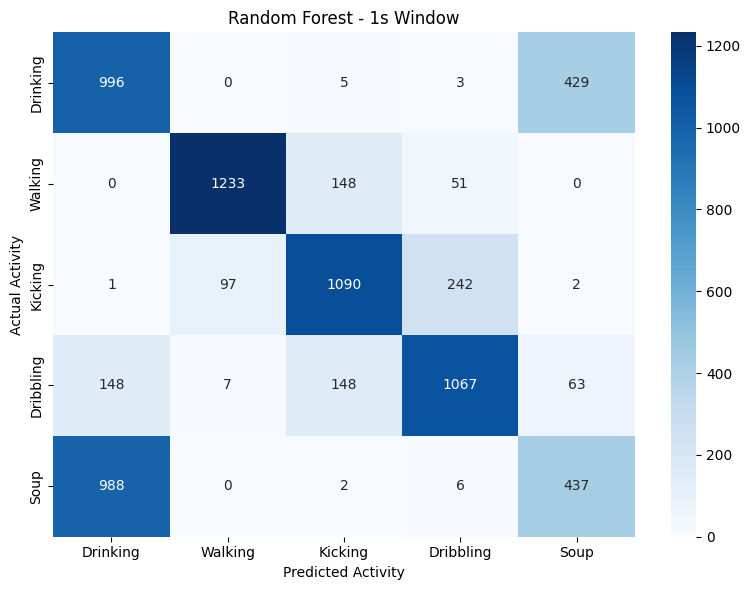

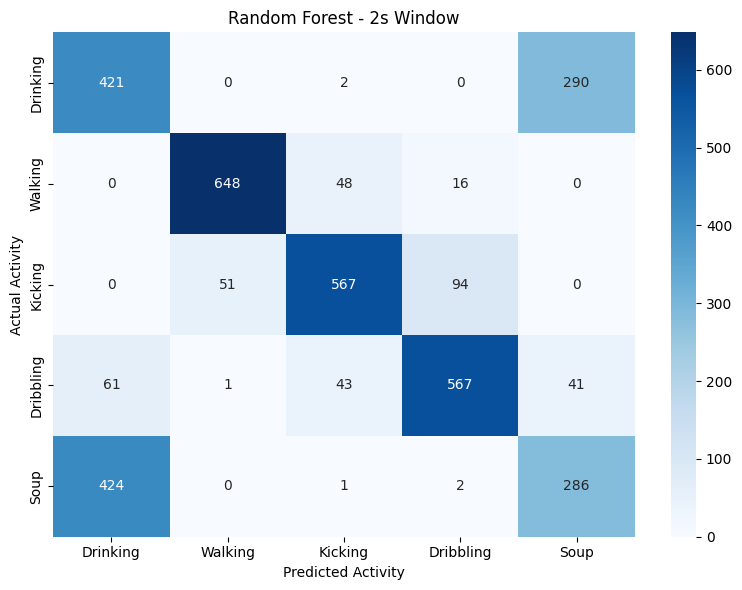

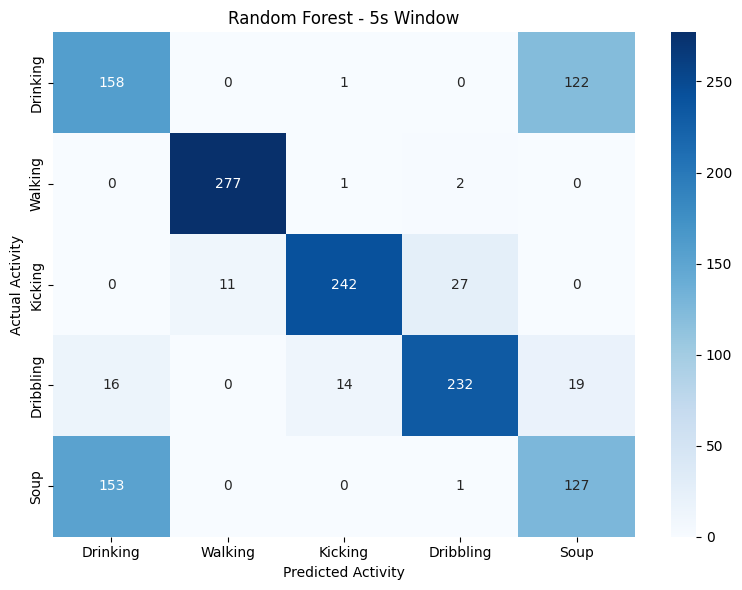

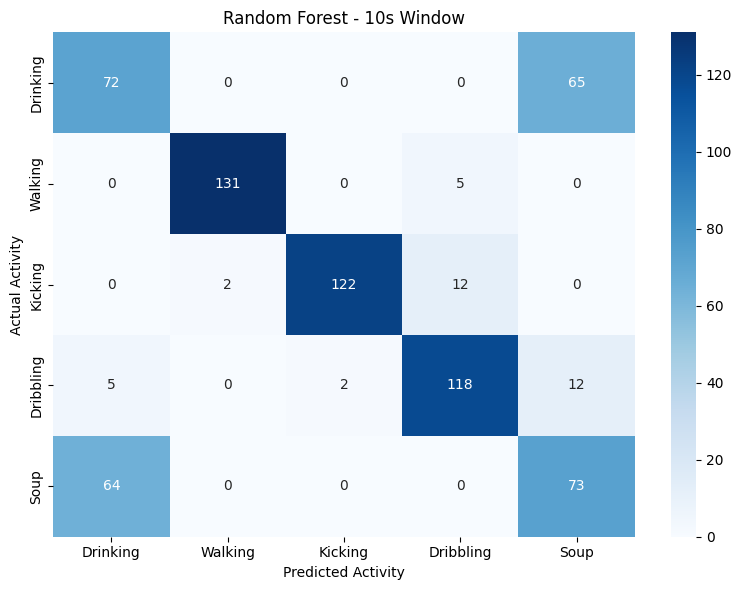

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

activity_names = [
    "Drinking",
    "Walking",
    "Kicking",
    "Dribbling",
    "Soup"
]

for window in window_sizes:

    data = datasets[window]
    model = models[window]

    X_val = data["X_val_unscaled"]
    y_val = data["y_val"]

    y_pred = model.predict(X_val)

    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1, 2, 3, 4]
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=activity_names,
        yticklabels=activity_names
    )

    plt.xlabel("Predicted Activity")
    plt.ylabel("Actual Activity")
    plt.title(f"Random Forest - {window}s Window")
    plt.tight_layout()
    plt.show()


In [8]:

from sklearn.metrics import classification_report

activity_names = [
    "Drinking",
    "Walking",
    "Kicking",
    "Dribbling",
    "Soup"
]

for window in window_sizes:

    data = datasets[window]
    model = models[window]

    X_val = data["X_val_unscaled"]
    y_val = data["y_val"]

    y_pred = model.predict(X_val)

    print(f"\n{'=' * 50}")
    print(f"Classification Report - {window}s Window")
    print(f"{'=' * 50}")

    print(classification_report(
        y_val,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=activity_names,
        digits=4,
        zero_division=0
    ))



Classification Report - 1s Window
              precision    recall  f1-score   support

    Drinking     0.4669    0.6950    0.5586      1433
     Walking     0.9222    0.8610    0.8906      1432
     Kicking     0.7825    0.7612    0.7717      1432
   Dribbling     0.7794    0.7446    0.7616      1433
        Soup     0.4694    0.3050    0.3697      1433

    accuracy                         0.6733      7163
   macro avg     0.6841    0.6734    0.6704      7163
weighted avg     0.6840    0.6733    0.6704      7163


Classification Report - 2s Window
              precision    recall  f1-score   support

    Drinking     0.4647    0.5905    0.5201       713
     Walking     0.9257    0.9101    0.9178       712
     Kicking     0.8578    0.7963    0.8259       712
   Dribbling     0.8351    0.7952    0.8147       713
        Soup     0.4635    0.4011    0.4301       713

    accuracy                         0.6986      3563
   macro avg     0.7094    0.6987    0.7017      3563
weighte

In [9]:

import os
import joblib

save_dir = "/content/drive/MyDrive/CS464-HAR-Project/results"

os.makedirs(save_dir, exist_ok=True)

for window in window_sizes:

    model = models[window]

    model_path = os.path.join(
        save_dir,
        f"random_forest_{window}s.joblib"
    )

    joblib.dump(model, model_path)

    print(f"{window}s model saved: {model_path}")

print("\nAll models saved successfully!")


1s model saved: /content/drive/MyDrive/CS464-HAR-Project/results/random_forest_1s.joblib
2s model saved: /content/drive/MyDrive/CS464-HAR-Project/results/random_forest_2s.joblib
5s model saved: /content/drive/MyDrive/CS464-HAR-Project/results/random_forest_5s.joblib
10s model saved: /content/drive/MyDrive/CS464-HAR-Project/results/random_forest_10s.joblib

All models saved successfully!
